# DISEASE: DIABETES

### 1.1. Reading the Dataset

### 1.2. General Information

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/diabetes_binary_health_indicators_BRFSS2015.csv")

print(df.shape)
df.info()

(253680, 22)
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15

### 2. Missing values

In [2]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "pct": missing_pct}).query("missing > 0")

,missing,pct


### 3. Summary stats

In [ ]:
df.describe(include="all").T

Exact duplicates: 24206


### 3.1. Target balance

In [3]:
df["Diabetes_binary"].value_counts(normalize=True).mul(100).round(2)

Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64

### 3.2. Duplicates

In [8]:
print("Exact duplicates:", df.duplicated().sum())

Exact duplicates: 24206


### 4. Correlation matrix

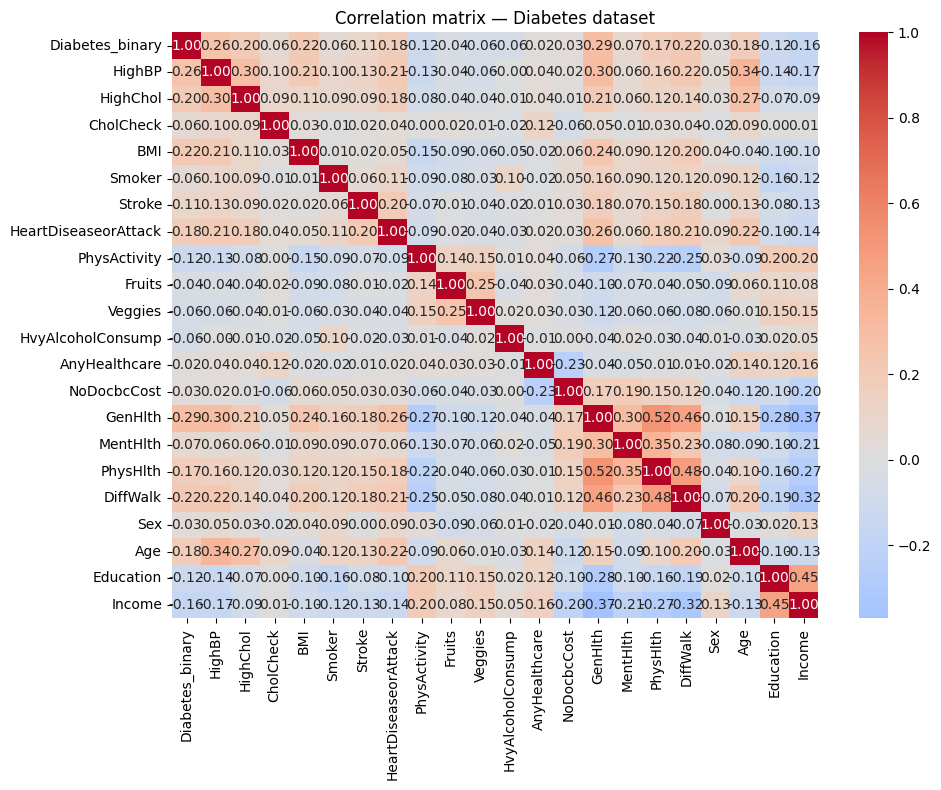

In [ ]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: Diabetes dataset")
plt.tight_layout()
plt.show()

### 5. Correlation with target, sorted

In [ ]:
target = "Diabetes_binary"
corr[target].drop(target).sort_values(key=abs, ascending=False)

GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Income                 -0.163919
Education              -0.124456
PhysActivity           -0.118133
Stroke                  0.105816
MentHlth                0.069315
CholCheck               0.064761
Smoker                  0.060789
HvyAlcoholConsump      -0.057056
Veggies                -0.056584
Fruits                 -0.040779
NoDocbcCost             0.031433
Sex                     0.031430
AnyHealthcare           0.016255
Name: Diabetes_binary, dtype: float64

In [2]:
print("Original rows:", len(df))
print("Exact duplicates:", df.duplicated().sum())

df_dedup = df.drop_duplicates()

print("After deduplication:", len(df_dedup))

Original rows: 253680
Exact duplicates: 24206
After deduplication: 229474
